# Feature Importance Analysis

Gain-based feature importance is used to evaluate the relative contribution of individual predictors to the fitted LightGBM model.

The final saved model is loaded directly without retraining.

In [9]:
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
import lightgbm as lgb

from config import MODEL_DIR, FIGURE_DIR, TABLE_DIR

## Load the trained model

In [2]:
saved = joblib.load(
    MODEL_DIR / "electricity_lightgbm_full.joblib"
)

model = saved["model"]
features = saved["features"]

print("Model:", saved["model_name"])
print("Number of features:", len(features))
print("Features:", features)
print("Training period:", saved["training_period"])

Model: LightGBM with Weather
Number of features: 10
Features: ['building_id', 'site_id', 'primary_use', 'square_feet', 'hour', 'day_of_week', 'month', 'air_temperature', 'dew_temperature', 'wind_speed']
Training period: 2016-01 to 2016-09


## Extract gain-based feature importance

Gain represents the total improvement in the training objective resulting from splits involving a particular feature.

The gain values are normalized to percentages for easier comparison among predictors.

In [3]:
importance = pd.DataFrame({
    "feature": model.booster_.feature_name(),

    "gain": model.booster_.feature_importance(
        importance_type="gain"
    ),

    "split": model.booster_.feature_importance(
        importance_type="split"
    )
})

importance["gain_percentage"] = (
    importance["gain"] / importance["gain"].sum() * 100
)

importance = importance.sort_values(
    "gain_percentage",
    ascending=False
).reset_index(drop=True)

importance

,feature,gain,split,gain_percentage
0,building_id,9.854408e+07,3772,50.730173
1,square_feet,8.995781e+07,300,46.309989
2,month,2.006355e+06,583,1.032865
3,hour,1.601619e+06,421,0.824509
4,day_of_week,7.564711e+05,226,0.389429
5,site_id,3.870996e+05,196,0.199278
6,air_temperature,3.287173e+05,183,0.169223
7,dew_temperature,3.052344e+05,179,0.157134
8,wind_speed,1.937510e+05,87,0.099742
9,primary_use,1.702789e+05,53,0.087659


## Visualize gain-based feature importance

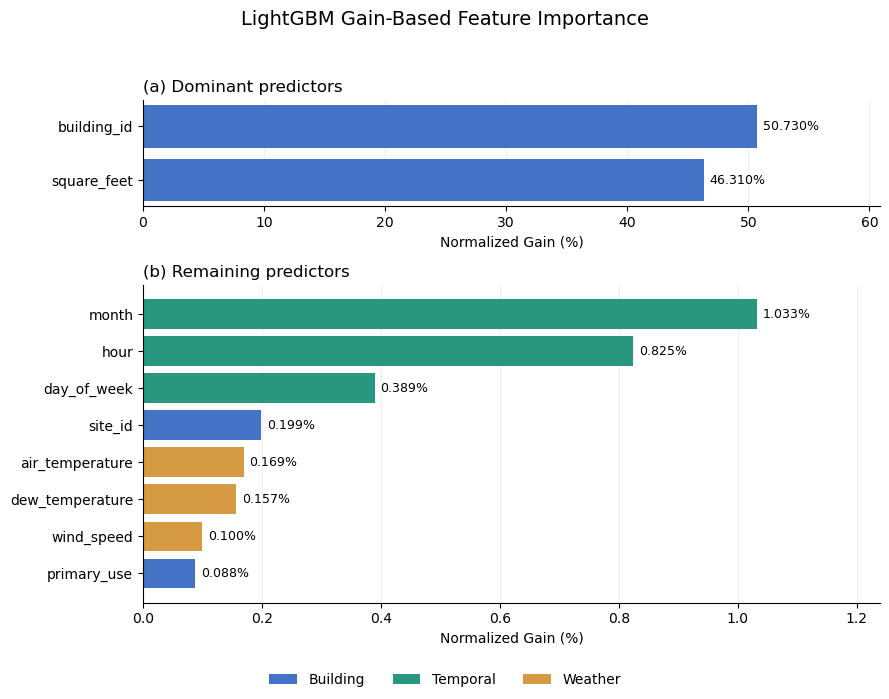

In [10]:
plot_data = importance.sort_values(
    "gain_percentage", ascending=False
).copy()

# Define colors for feature groups
colors = {
    "Building": "#4472C4",
    "Temporal": "#299780",
    "Weather": "#D59A42"
}

# Split features into two panels
dominant = plot_data.iloc[:2]
remaining = plot_data.iloc[2:]

fig, axes = plt.subplots(
    2, 1,
    figsize=(9, 7),
    gridspec_kw={"height_ratios": [1, 3]}
)

for ax, data, title in [
    (axes[0], dominant, "(a) Dominant predictors"),
    (axes[1], remaining, "(b) Remaining predictors")
]:
    bars = ax.barh(
        data["feature"],
        data["gain_percentage"],
        color=data["group"].map(colors)
    )

    ax.invert_yaxis()
    ax.set_title(title, loc="left")
    ax.set_xlabel("Normalized Gain (%)")
    ax.set_xlim(0, data["gain_percentage"].max() * 1.20)

    ax.bar_label(
        bars,
        fmt="%.3f%%",
        padding=4,
        fontsize=9
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

# Common legend
legend_elements = [
    Patch(facecolor=color, label=group)
    for group, color in colors.items()
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=3,
    frameon=False
)

fig.suptitle(
    "LightGBM Gain-Based Feature Importance",
    fontsize=14
)

plt.tight_layout(rect=[0, 0.05, 1, 0.95])

plt.savefig(
    FIGURE_DIR / "lightgbm_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Save feature importance results

In [5]:
importance.to_csv(
    TABLE_DIR / "lightgbm_feature_importance.csv",
    index=False
)

print("Feature importance results saved.")

Feature importance results saved.


## Feature importance by variable group

In [6]:
feature_groups = {
    "building_id": "Building",
    "site_id": "Building",
    "primary_use": "Building",
    "square_feet": "Building",

    "hour": "Temporal",
    "day_of_week": "Temporal",
    "month": "Temporal",

    "air_temperature": "Weather",
    "dew_temperature": "Weather",
    "wind_speed": "Weather"
}

importance["group"] = importance["feature"].map(
    feature_groups
)

group_importance = (
    importance.groupby("group")["gain_percentage"]
    .sum()
    .reset_index()
    .sort_values("gain_percentage", ascending=False)
)

group_importance

,group,gain_percentage
0,Building,97.327099
1,Temporal,2.246803
2,Weather,0.426099


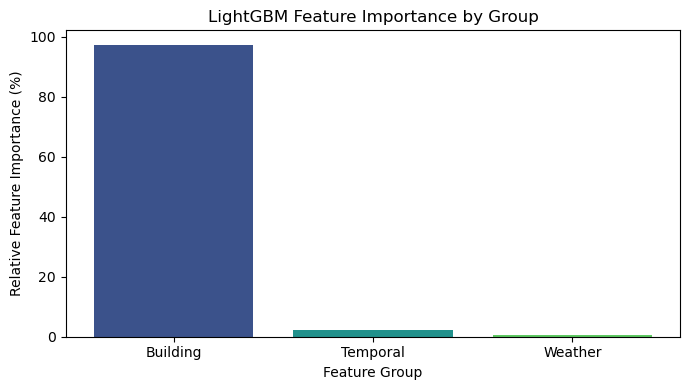

In [7]:
plt.figure(figsize=(7, 4))

plt.bar(
    group_importance["group"],
    group_importance["gain_percentage"],
    color=sns.color_palette("viridis", n_colors=len(group_importance))
)

plt.title("LightGBM Feature Importance by Group")
plt.xlabel("Feature Group")
plt.ylabel("Relative Feature Importance (%)")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "lightgbm_group_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Save group-wise results

In [8]:
group_importance.to_csv(
    TABLE_DIR / "lightgbm_group_importance.csv",
    index=False
)